In [1]:
import numpy as np
import json
import matplotlib.pyplot as plt
from time import sleep
import seaborn as sns


In [5]:
dejmps_data = []
bbpssw_data = []

dejmps_data_focused = []
bbpssw_data_focused = []

def format_the_data(combined_list: list) -> list:
    extracted_data = []
    for data in combined_list:
        link_conf = data['conf']['links'][0]
        node_conf = data['conf']['nodes']
        alice_conf = None
        bob_conf = None
        for i in range(len(node_conf)):
            if node_conf[i]['name'] == 'delft': # Alice
                alice_conf = node_conf[i]
            if node_conf[i]['name'] == 'the_hague': # Bob
                bob_conf = node_conf[i]
        if alice_conf is None or bob_conf is None:
            raise ValueError('Alice or Bob configuration not found')
        new_data = {
            'link_f': link_conf['fidelity'],
            'alice_f': alice_conf['gate_fidelity'],
            'bob_f': bob_conf['gate_fidelity'],
            'success_f': data['success_f'],
            'failed_f': data['failed_f'],
        }
        
        extracted_data.append(new_data)
    return extracted_data

with open('dejmps/total_combined.json', 'r') as f:
    dejmps_data = format_the_data(json.load(f))

with open('bbpssw/total_combined.json', 'r') as f:
    bbpssw_data = format_the_data(json.load(f))

with open('dejmps/total_combined_fidelityff.json', 'r') as f:
    dejmps_data_focused = format_the_data(json.load(f))

with open('bbpssw/total_combined_fidelityf.json', 'r') as f:
    bbpssw_data_focused = format_the_data(json.load(f))

print(len(dejmps_data))
print(len(bbpssw_data))
print(len(dejmps_data_focused))
print(len(bbpssw_data_focused))


216
216
60
60


In [6]:
def extract_data(data: list, link_fidelity=None, alice_fidelity=None, bob_fidelity=None) -> list:
    extract_data = []
    for element in data:
        link_condition = True
        alice_condition = True
        bob_condition = True
        if link_fidelity is not None and not link_fidelity(element['link_f']):
            link_condition = False
        if alice_fidelity is not None and not alice_fidelity(element['alice_f']):
            alice_condition = False
        if bob_fidelity is not None and not bob_fidelity(element['bob_f']):
            bob_condition = False
        if link_condition and alice_condition and bob_condition:
            extract_data.append(element)
    return extract_data

def get_success_rate(data: dict) -> float:
    return len(data['success_f']) / (len(data['success_f']) + len(data['failed_f']))

def get_avg(data: list, key: str) -> float:
    return np.mean([element[key] for element in data])

def get_median(data: list, key: str) -> float:
    return np.median([element[key] for element in data])

def get_std(data: list, key: str) -> float:
    return np.std([element[key] for element in data])

def get_min(data: list, key: str) -> float:
    return np.min([element[key] for element in data])

def get_max(data: list, key: str) -> float:
    return np.max([element[key] for element in data])


def add_statistics(data: list) -> list:
    new_list = []
    for element in data:
        new_element = element.copy()
        new_element['success_rate'] = get_success_rate(element)
        new_element['avg_success_fidelity'] = get_avg(element['success_f'], 'fidelity')
        new_element['avg_success_fidelityZ'] = get_avg(element['success_f'], 'fidelityZ')
        new_element['avg_success_fidelity2Z'] = get_avg(element['success_f'], 'fidelity2Z')
        new_element['avg_success_fidelityI'] = get_avg(element['success_f'], 'fidelityI')
        new_element['avg_success_fidelity_or1'] = get_avg(element['success_f'], 'or_fidelity1')
        new_element['avg_success_fidelity_or2'] = get_avg(element['success_f'], 'or_fidelity2')
        new_list.append(new_element)
    return new_list
  

In [7]:
# data for link degradation only
alice_fidelity = lambda x: x==1
bob_fidelity = lambda x: x==1
dejmps_link_degradation = extract_data(dejmps_data, alice_fidelity=alice_fidelity, bob_fidelity=bob_fidelity)
bbpssw_link_degradation = extract_data(bbpssw_data, alice_fidelity=alice_fidelity, bob_fidelity=bob_fidelity)
dejmps_link_degradation = add_statistics(dejmps_link_degradation)
print(len(dejmps_link_degradation))
print(len(bbpssw_link_degradation))


6
6


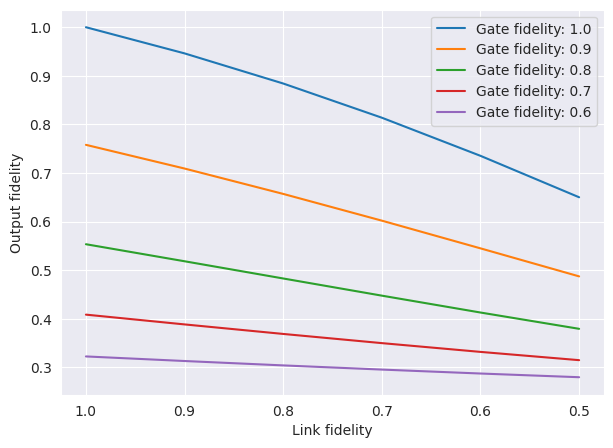

In [8]:
datasets=[]
datasets2 = []
for i in reversed(range(6, 11)):
    alice_fidelity = lambda x: x==i/10
    bob_fidelity = lambda x: x==i/10
    dejmps_link_degradation_t = extract_data(dejmps_data, alice_fidelity=alice_fidelity, bob_fidelity=bob_fidelity)
    bbpssw_link_degradation_t = extract_data(bbpssw_data, alice_fidelity=alice_fidelity, bob_fidelity=bob_fidelity)
    dejmps_link_degradation_t = add_statistics(dejmps_link_degradation_t)
    bbpssw_link_degradation_t = add_statistics(bbpssw_link_degradation_t)
    datasets.append(dejmps_link_degradation_t)
    datasets2.append(bbpssw_link_degradation_t)
sns.set_style("darkgrid")
plt.figure(figsize=(7, 5))
plt.xlabel('Link fidelity')
plt.ylabel('Output fidelity')
for dataset in datasets:
    dejmps_link_sr = sorted(dataset, key=lambda x: x['link_f'], reverse=False)
    x_data = [element['link_f'] for element in dejmps_link_sr]
    y_data = [element['avg_success_fidelity'] for element in dejmps_link_sr]    
    plt.plot(x_data, y_data, label=f"Gate fidelity: {str(dataset[0]['alice_f'])}")
    # plt.boxplot(y_box, labels=x_data, widths=0.1, )
plt.gca().invert_xaxis()
plt.legend(loc="upper right")
plt.show()



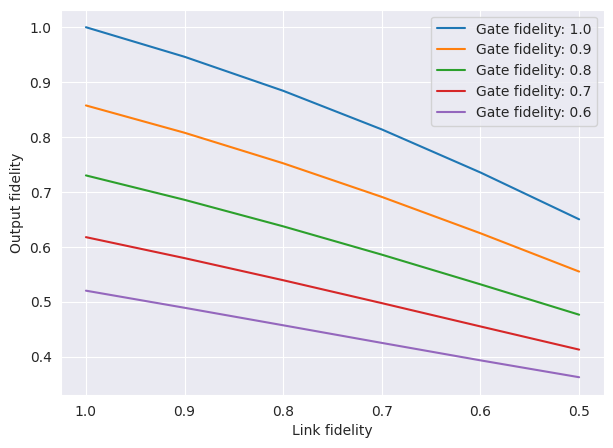

In [9]:
sns.set_style("darkgrid")
plt.figure(figsize=(7, 5))
plt.xlabel('Link fidelity')
plt.ylabel('Output fidelity')
for dataset in datasets2:
    dejmps_link_sr = sorted(dataset, key=lambda x: x['link_f'], reverse=False)
    x_data = [element['link_f'] for element in dejmps_link_sr]
    y_data = [element['avg_success_fidelity'] for element in dejmps_link_sr]    
    plt.plot(x_data, y_data, label=f"Gate fidelity: {str(dataset[0]['alice_f'])}")
    # plt.boxplot(y_box, labels=x_data, widths=0.1, )
plt.gca().invert_xaxis()
plt.legend(loc="upper right")
plt.show()


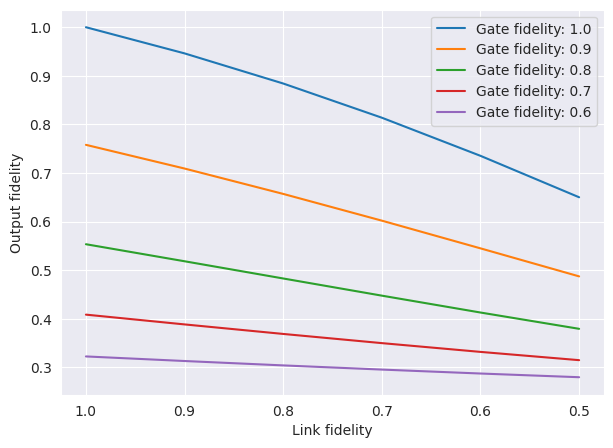

In [10]:
sns.set_style("darkgrid")
plt.figure(figsize=(7, 5))
plt.xlabel('Link fidelity')
plt.ylabel('Output fidelity')
for dataset in datasets:
    dejmps_link_sr = sorted(dataset, key=lambda x: x['link_f'], reverse=False)
    x_data = [element['link_f'] for element in dejmps_link_sr]
    y_data = [element['avg_success_fidelity'] for element in dejmps_link_sr]
    plt.plot(x_data, y_data, label=f"Gate fidelity: {str(dataset[0]['alice_f'])}")
plt.gca().invert_xaxis()
plt.legend(loc="upper right")
plt.show()

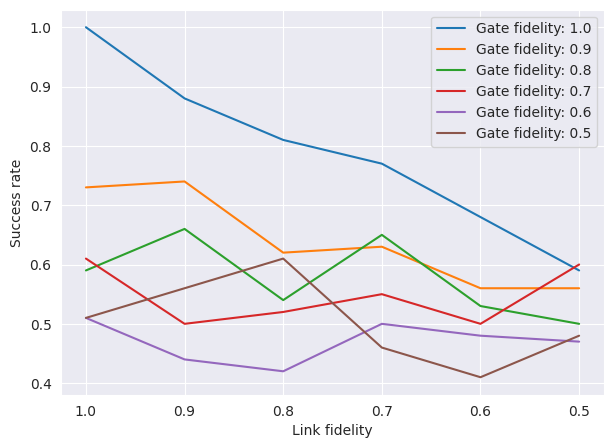

In [11]:
#Success rate vs link fidelity
datasets=[]
datasets2 = []
for i in reversed(range(5, 11)):
    alice_fidelity = lambda x: x==i/10
    bob_fidelity = lambda x: x==i/10
    dejmps_link_degradation_t = extract_data(dejmps_data, alice_fidelity=alice_fidelity, bob_fidelity=bob_fidelity)
    bbpssw_link_degradation_t = extract_data(bbpssw_data, alice_fidelity=alice_fidelity, bob_fidelity=bob_fidelity)
    dejmps_link_degradation_t = add_statistics(dejmps_link_degradation_t)
    bbpssw_link_degradation_t = add_statistics(bbpssw_link_degradation_t)
    datasets.append(dejmps_link_degradation_t)
    datasets2.append(bbpssw_link_degradation_t)
sns.set_style("darkgrid")
plt.figure(figsize=(7, 5))
plt.xlabel('Link fidelity')
plt.ylabel('Success rate')

for dataset in datasets:
    dejmps_link_sr = sorted(dataset, key=lambda x: x['link_f'], reverse=False)
    x_data = [element['link_f'] for element in dejmps_link_sr]
    y_data = [element['success_rate'] for element in dejmps_link_sr]
    plt.plot(x_data, y_data, label=f"Gate fidelity: {str(dataset[0]['alice_f'])}")
plt.gca().invert_xaxis()
plt.legend(loc="upper right")
plt.show()

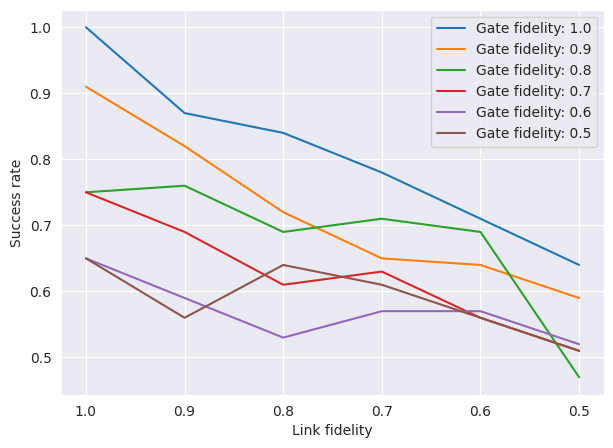

In [12]:
sns.set_style("darkgrid")
plt.figure(figsize=(7, 5))
plt.xlabel('Link fidelity')
plt.ylabel('Success rate')

for dataset in datasets2:
    bbpssw_link_sr = sorted(dataset, key=lambda x: x['link_f'], reverse=False)
    x_data = [element['link_f'] for element in bbpssw_link_sr]
    y_data = [element['success_rate'] for element in bbpssw_link_sr]
    plt.plot(x_data, y_data, label=f"Gate fidelity: {str(dataset[0]['alice_f'])}")
plt.gca().invert_xaxis()
plt.legend(loc="upper right")
plt.show()

[0.6499980338983051, 0.7352915235294119, 0.813755005194805, 0.8841424975308643, 0.9461284295454546, 0.9999955199999999]
[0.379237294, 0.4127833849056604, 0.4475128815384615, 0.48285404444444435, 0.5182889803030302, 0.5533661423728813]


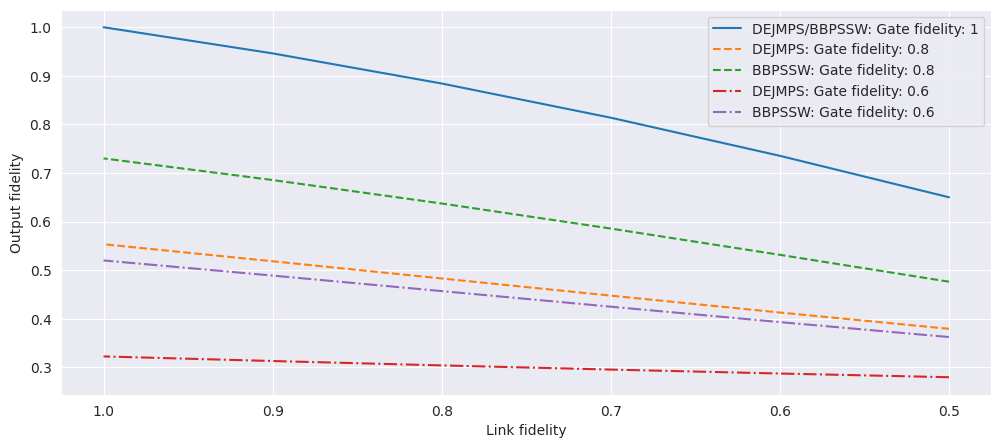

In [13]:
#DEJMPS vs BBPSSW Link fidelity - output fidelity

filtered_dataset_dejmps = extract_data(dejmps_data, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
filtered_dataset_dejmps = add_statistics(filtered_dataset_dejmps)
filtered_dataset_bbpssw = extract_data(bbpssw_data, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
filtered_dataset_bbpssw = add_statistics(filtered_dataset_bbpssw)

filtered_dataset_dejmps2 = extract_data(dejmps_data, alice_fidelity=lambda x: x==0.8, bob_fidelity=lambda x: x==0.8)
filtered_dataset_dejmps2 = add_statistics(filtered_dataset_dejmps2)
filtered_dataset_bbpssw2 = extract_data(bbpssw_data, alice_fidelity=lambda x: x==0.8, bob_fidelity=lambda x: x==0.8)
filtered_dataset_bbpssw2 = add_statistics(filtered_dataset_bbpssw2)

filtered_dataset_dejmps3 = extract_data(dejmps_data, alice_fidelity=lambda x: x==0.6, bob_fidelity=lambda x: x==0.6)
filtered_dataset_dejmps3 = add_statistics(filtered_dataset_dejmps3)
filtered_dataset_bbpssw3 = extract_data(bbpssw_data, alice_fidelity=lambda x: x==0.6, bob_fidelity=lambda x: x==0.6)
filtered_dataset_bbpssw3 = add_statistics(filtered_dataset_bbpssw3)

sns.set_style("darkgrid")
plt.figure(figsize=(12, 5))
plt.xlabel('Link fidelity')
plt.ylabel('Output fidelity')
dejmps_link_sr = sorted(filtered_dataset_dejmps, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr = sorted(filtered_dataset_bbpssw, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr2 = sorted(filtered_dataset_dejmps2, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr2 = sorted(filtered_dataset_bbpssw2, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr3 = sorted(filtered_dataset_dejmps3, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr3 = sorted(filtered_dataset_bbpssw3, key=lambda x: x['link_f'], reverse=False)
x_data_dejmps = [element['link_f'] for element in dejmps_link_sr]
y_data_dejmps = [element['avg_success_fidelity'] for element in dejmps_link_sr]
x_data_bbpssw = [element['link_f'] for element in bbpssw_link_sr]
y_data_bbpssw = [element['avg_success_fidelity'] for element in bbpssw_link_sr]

x_data_dejmps2 = [element['link_f'] for element in dejmps_link_sr2]
y_data_dejmps2 = [element['avg_success_fidelity'] for element in dejmps_link_sr2]
x_data_bbpssw2 = [element['link_f'] for element in bbpssw_link_sr2]
y_data_bbpssw2 = [element['avg_success_fidelity'] for element in bbpssw_link_sr2]

x_data_dejmps3 = [element['link_f'] for element in dejmps_link_sr3]
y_data_dejmps3 = [element['avg_success_fidelity'] for element in dejmps_link_sr3]
x_data_bbpssw3 = [element['link_f'] for element in bbpssw_link_sr3]
y_data_bbpssw3 = [element['avg_success_fidelity'] for element in bbpssw_link_sr3]

print(y_data_dejmps)
print(y_data_dejmps2)
plt.plot(x_data_dejmps, y_data_dejmps, label='DEJMPS/BBPSSW: Gate fidelity: 1')
# plt.plot(x_data_bbpssw, y_data_bbpssw, label='BBPSSW: Gate fidelity: 1')
plt.plot(x_data_dejmps2, y_data_dejmps2, label='DEJMPS: Gate fidelity: 0.8', linestyle='dashed')
plt.plot(x_data_bbpssw2, y_data_bbpssw2, label='BBPSSW: Gate fidelity: 0.8', linestyle='dashed')
plt.plot(x_data_dejmps3, y_data_dejmps3, label='DEJMPS: Gate fidelity: 0.6', linestyle='-.')
plt.plot(x_data_bbpssw3, y_data_bbpssw3, label='BBPSSW: Gate fidelity: 0.6', linestyle='-.')
plt.gca().invert_xaxis()
plt.legend(loc="upper right")
plt.show()

[0.59, 0.68, 0.77, 0.81, 0.88, 1.0]
[0.5, 0.53, 0.65, 0.54, 0.66, 0.59]


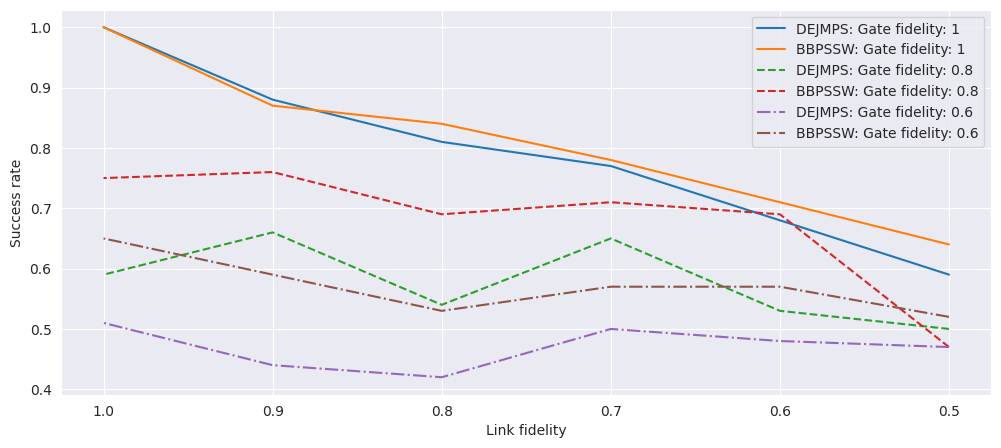

In [14]:
#DEJMPS vs BBPSSW Link fidelity - success rate

filtered_dataset_dejmps = extract_data(dejmps_data, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
filtered_dataset_dejmps = add_statistics(filtered_dataset_dejmps)
filtered_dataset_bbpssw = extract_data(bbpssw_data, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
filtered_dataset_bbpssw = add_statistics(filtered_dataset_bbpssw)

filtered_dataset_dejmps2 = extract_data(dejmps_data, alice_fidelity=lambda x: x==0.8, bob_fidelity=lambda x: x==0.8)
filtered_dataset_dejmps2 = add_statistics(filtered_dataset_dejmps2)
filtered_dataset_bbpssw2 = extract_data(bbpssw_data, alice_fidelity=lambda x: x==0.8, bob_fidelity=lambda x: x==0.8)
filtered_dataset_bbpssw2 = add_statistics(filtered_dataset_bbpssw2)

filtered_dataset_dejmps3 = extract_data(dejmps_data, alice_fidelity=lambda x: x==0.6, bob_fidelity=lambda x: x==0.6)
filtered_dataset_dejmps3 = add_statistics(filtered_dataset_dejmps3)
filtered_dataset_bbpssw3 = extract_data(bbpssw_data, alice_fidelity=lambda x: x==0.6, bob_fidelity=lambda x: x==0.6)
filtered_dataset_bbpssw3 = add_statistics(filtered_dataset_bbpssw3)


sns.set_style("darkgrid")
plt.figure(figsize=(12, 5))
plt.xlabel('Link fidelity')
plt.ylabel('Success rate')
dejmps_link_sr = sorted(filtered_dataset_dejmps, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr = sorted(filtered_dataset_bbpssw, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr2 = sorted(filtered_dataset_dejmps2, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr2 = sorted(filtered_dataset_bbpssw2, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr3 = sorted(filtered_dataset_dejmps3, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr3 = sorted(filtered_dataset_bbpssw3, key=lambda x: x['link_f'], reverse=False)
x_data_dejmps = [element['link_f'] for element in dejmps_link_sr]
y_data_dejmps = [element['success_rate'] for element in dejmps_link_sr]
x_data_bbpssw = [element['link_f'] for element in bbpssw_link_sr]
y_data_bbpssw = [element['success_rate'] for element in bbpssw_link_sr]

x_data_dejmps2 = [element['link_f'] for element in dejmps_link_sr2]
y_data_dejmps2 = [element['success_rate'] for element in dejmps_link_sr2]
x_data_bbpssw2 = [element['link_f'] for element in bbpssw_link_sr2]
y_data_bbpssw2 = [element['success_rate'] for element in bbpssw_link_sr2]

x_data_dejmps3 = [element['link_f'] for element in dejmps_link_sr3]
y_data_dejmps3 = [element['success_rate'] for element in dejmps_link_sr3]
x_data_bbpssw3 = [element['link_f'] for element in bbpssw_link_sr3]
y_data_bbpssw3 = [element['success_rate'] for element in bbpssw_link_sr3]

print(y_data_dejmps)
print(y_data_dejmps2)
plt.plot(x_data_dejmps, y_data_dejmps, label='DEJMPS: Gate fidelity: 1')
plt.plot(x_data_bbpssw, y_data_bbpssw, label='BBPSSW: Gate fidelity: 1')
plt.plot(x_data_dejmps2, y_data_dejmps2, label='DEJMPS: Gate fidelity: 0.8', linestyle='dashed')
plt.plot(x_data_bbpssw2, y_data_bbpssw2, label='BBPSSW: Gate fidelity: 0.8', linestyle='dashed')
plt.plot(x_data_dejmps3, y_data_dejmps3, label='DEJMPS: Gate fidelity: 0.6', linestyle='-.')
plt.plot(x_data_bbpssw3, y_data_bbpssw3, label='BBPSSW: Gate fidelity: 0.6', linestyle='-.')
plt.gca().invert_xaxis()
plt.legend(loc="upper right")
plt.show()

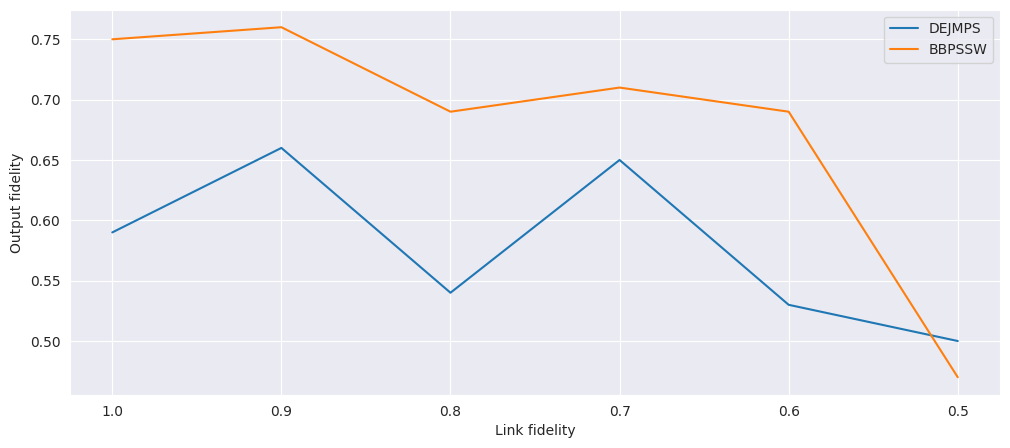

In [15]:
filtered_dataset_dejmps = extract_data(dejmps_data, alice_fidelity=lambda x: x==0.8, bob_fidelity=lambda x: x==0.8)
filtered_dataset_dejmps = add_statistics(filtered_dataset_dejmps)
filtered_dataset_bbpssw = extract_data(bbpssw_data, alice_fidelity=lambda x: x==0.8, bob_fidelity=lambda x: x==0.8)
filtered_dataset_bbpssw = add_statistics(filtered_dataset_bbpssw)

sns.set_style("darkgrid")
plt.figure(figsize=(12, 5))
plt.xlabel('Link fidelity')
plt.ylabel('Output fidelity')
dejmps_link_sr = sorted(filtered_dataset_dejmps, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr = sorted(filtered_dataset_bbpssw, key=lambda x: x['link_f'], reverse=False)
x_data_dejmps = [element['link_f'] for element in dejmps_link_sr]
y_data_dejmps = [element['success_rate'] for element in dejmps_link_sr]
x_data_bbpssw = [element['link_f'] for element in bbpssw_link_sr]
y_data_bbpssw = [element['success_rate'] for element in bbpssw_link_sr]
plt.plot(x_data_dejmps, y_data_dejmps, label='DEJMPS')
plt.plot(x_data_bbpssw, y_data_bbpssw, label='BBPSSW')
plt.gca().invert_xaxis()
plt.legend(loc="upper right")
plt.show()

[0.6499980338983051, 0.7352915235294119, 0.813755005194805, 0.8841424975308643, 0.9461284295454546, 0.9999955199999999]
[0.379237294, 0.4127833849056604, 0.4475128815384615, 0.48285404444444435, 0.5182889803030302, 0.5533661423728813]


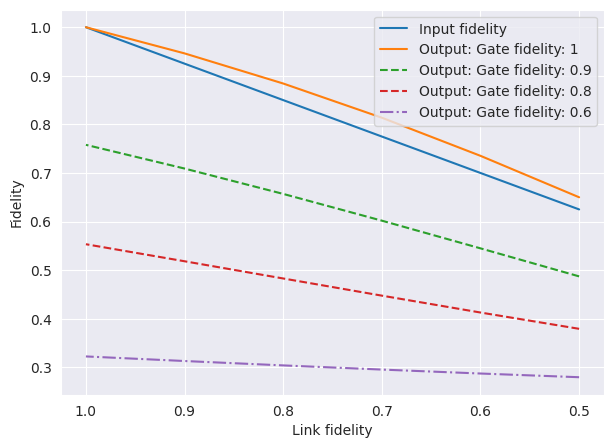

In [16]:
#DEJMPS vs BBPSSW Link fidelity - output fidelity

filtered_dataset_dejmps = extract_data(dejmps_data, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
filtered_dataset_dejmps = add_statistics(filtered_dataset_dejmps)
# filtered_dataset_bbpssw = extract_data(bbpssw_data, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
# filtered_dataset_bbpssw = add_statistics(filtered_dataset_bbpssw)

filtered_dataset_dejmps4 = extract_data(dejmps_data, alice_fidelity=lambda x: x==0.9, bob_fidelity=lambda x: x==0.9)
filtered_dataset_dejmps4 = add_statistics(filtered_dataset_dejmps4)

filtered_dataset_dejmps2 = extract_data(dejmps_data, alice_fidelity=lambda x: x==0.8, bob_fidelity=lambda x: x==0.8)
filtered_dataset_dejmps2 = add_statistics(filtered_dataset_dejmps2)
# filtered_dataset_bbpssw2 = extract_data(bbpssw_data, alice_fidelity=lambda x: x==0.8, bob_fidelity=lambda x: x==0.8)
# filtered_dataset_bbpssw2 = add_statistics(filtered_dataset_bbpssw2)

filtered_dataset_dejmps3 = extract_data(dejmps_data, alice_fidelity=lambda x: x==0.6, bob_fidelity=lambda x: x==0.6)
filtered_dataset_dejmps3 = add_statistics(filtered_dataset_dejmps3)
# filtered_dataset_bbpssw3 = extract_data(bbpssw_data, alice_fidelity=lambda x: x==0.6, bob_fidelity=lambda x: x==0.6)
# filtered_dataset_bbpssw3 = add_statistics(filtered_dataset_bbpssw3)

sns.set_style("darkgrid")
plt.figure(figsize=(7, 5))
plt.xlabel('Link fidelity')
plt.ylabel('Fidelity')
dejmps_link_sr = sorted(filtered_dataset_dejmps, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr2 = sorted(filtered_dataset_dejmps2, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr3 = sorted(filtered_dataset_dejmps3, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr4 = sorted(filtered_dataset_dejmps4, key=lambda x: x['link_f'], reverse=False)
x_data_dejmps = [element['link_f'] for element in dejmps_link_sr]
y_data_dejmps = [element['avg_success_fidelity'] for element in dejmps_link_sr]
x_data_dejmps_or = [element['link_f'] for element in dejmps_link_sr]
y_data_dejmps_or = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr]

x_data_dejmps4 = [element['link_f'] for element in dejmps_link_sr4]
y_data_dejmps4 = [element['avg_success_fidelity'] for element in dejmps_link_sr4]
x_data_dejmps_or4 = [element['link_f'] for element in dejmps_link_sr4]
y_data_dejmps_or4 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr4]

x_data_dejmps2 = [element['link_f'] for element in dejmps_link_sr2]
y_data_dejmps2 = [element['avg_success_fidelity'] for element in dejmps_link_sr2]
x_data_dejmps_or2 = [element['link_f'] for element in dejmps_link_sr2]
y_data_dejmps_or2 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr2]

x_data_dejmps3 = [element['link_f'] for element in dejmps_link_sr3]
y_data_dejmps3 = [element['avg_success_fidelity'] for element in dejmps_link_sr3]
x_data_dejmps_or3 = [element['link_f'] for element in dejmps_link_sr3]
y_data_dejmps_or3 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr3]

print(y_data_dejmps)
print(y_data_dejmps2)
plt.plot(x_data_dejmps_or, y_data_dejmps_or, label='Input fidelity')
plt.plot(x_data_dejmps, y_data_dejmps, label='Output: Gate fidelity: 1')
# plt.plot(x_data_dejmps_or, y_data_dejmps_or, label='Input: Gate fidelity: 1')
plt.plot(x_data_dejmps4, y_data_dejmps4, label='Output: Gate fidelity: 0.9', linestyle='dashed')
plt.plot(x_data_dejmps2, y_data_dejmps2, label='Output: Gate fidelity: 0.8', linestyle='dashed')
# plt.plot(x_data_dejmps_or2, y_data_dejmps_or2, label='Input: Gate fidelity: 0.8', linestyle='dashed')
plt.plot(x_data_dejmps3, y_data_dejmps3, label='Output: Gate fidelity: 0.6', linestyle='-.')
# plt.plot(x_data_dejmps_or3, y_data_dejmps_or3, label='Input: Gate fidelity: 0.6', linestyle='-.')
plt.gca().invert_xaxis()
plt.legend(loc="upper right")
plt.show()

[0.6499969921875, 0.73529038028169, 0.8137534397435897, 0.8841406511904762, 0.9461256517241377, 0.9999926180000002]
[0.47620481489361705, 0.5315056159420289, 0.5855870464788732, 0.6371919217391303, 0.6854849894736842, 0.7299940506666668]


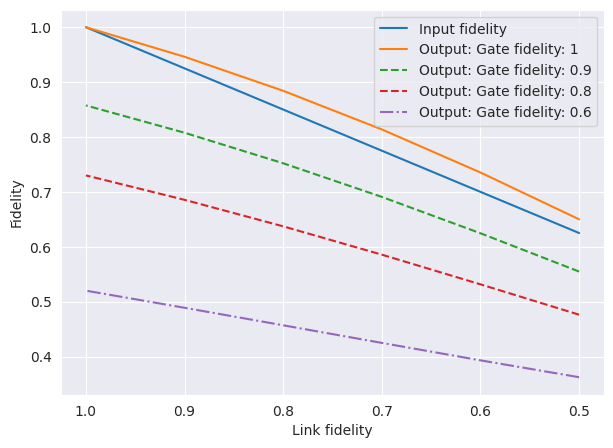

In [17]:


# filtered_dataset_dejmps = extract_data(dejmps_data, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
# filtered_dataset_dejmps = add_statistics(filtered_dataset_dejmps)
filtered_dataset_bbpssw = extract_data(bbpssw_data, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
filtered_dataset_bbpssw = add_statistics(filtered_dataset_bbpssw)

filtered_dataset_bbpssw4= extract_data(bbpssw_data, alice_fidelity=lambda x: x==0.9, bob_fidelity=lambda x: x==0.9)
filtered_dataset_bbpssw4 = add_statistics(filtered_dataset_bbpssw4)

# filtered_dataset_dejmps2 = extract_data(dejmps_data, alice_fidelity=lambda x: x==0.8, bob_fidelity=lambda x: x==0.8)
# filtered_dataset_dejmps2 = add_statistics(filtered_dataset_dejmps2)
filtered_dataset_bbpssw2 = extract_data(bbpssw_data, alice_fidelity=lambda x: x==0.8, bob_fidelity=lambda x: x==0.8)
filtered_dataset_bbpssw2 = add_statistics(filtered_dataset_bbpssw2)

# filtered_dataset_dejmps3 = extract_data(dejmps_data, alice_fidelity=lambda x: x==0.6, bob_fidelity=lambda x: x==0.6)
# filtered_dataset_dejmps3 = add_statistics(filtered_dataset_dejmps3)
filtered_dataset_bbpssw3 = extract_data(bbpssw_data, alice_fidelity=lambda x: x==0.6, bob_fidelity=lambda x: x==0.6)
filtered_dataset_bbpssw3 = add_statistics(filtered_dataset_bbpssw3)

sns.set_style("darkgrid")
plt.figure(figsize=(7, 5))
plt.xlabel('Link fidelity')
plt.ylabel('Fidelity')
dejmps_link_sr = sorted(filtered_dataset_bbpssw, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr2 = sorted(filtered_dataset_bbpssw2, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr3 = sorted(filtered_dataset_bbpssw3, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr4 = sorted(filtered_dataset_bbpssw4, key=lambda x: x['link_f'], reverse=False)

x_data_dejmps = [element['link_f'] for element in dejmps_link_sr]
y_data_dejmps = [element['avg_success_fidelity'] for element in dejmps_link_sr]
x_data_dejmps_or = [element['link_f'] for element in dejmps_link_sr]
y_data_dejmps_or = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr]

x_data_dejmps4 = [element['link_f'] for element in dejmps_link_sr4]
y_data_dejmps4 = [element['avg_success_fidelity'] for element in dejmps_link_sr4]
x_data_dejmps_or4 = [element['link_f'] for element in dejmps_link_sr4]
y_data_dejmps_or4 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr4]

x_data_dejmps2 = [element['link_f'] for element in dejmps_link_sr2]
y_data_dejmps2 = [element['avg_success_fidelity'] for element in dejmps_link_sr2]
x_data_dejmps_or2 = [element['link_f'] for element in dejmps_link_sr2]
y_data_dejmps_or2 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr2]

x_data_dejmps3 = [element['link_f'] for element in dejmps_link_sr3]
y_data_dejmps3 = [element['avg_success_fidelity'] for element in dejmps_link_sr3]
x_data_dejmps_or3 = [element['link_f'] for element in dejmps_link_sr3]
y_data_dejmps_or3 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr3]

print(y_data_dejmps)
print(y_data_dejmps2)
plt.plot(x_data_dejmps_or, y_data_dejmps_or, label='Input fidelity')
plt.plot(x_data_dejmps, y_data_dejmps, label='Output: Gate fidelity: 1')
plt.plot(x_data_dejmps4, y_data_dejmps4, label='Output: Gate fidelity: 0.9', linestyle='dashed')
plt.plot(x_data_dejmps2, y_data_dejmps2, label='Output: Gate fidelity: 0.8', linestyle='dashed')
# plt.plot(x_data_dejmps_or2, y_data_dejmps_or2, label='Input: Gate fidelity: 0.8', linestyle='dashed')
plt.plot(x_data_dejmps3, y_data_dejmps3, label='Output: Gate fidelity: 0.6', linestyle='-.')
# plt.plot(x_data_dejmps_or3, y_data_dejmps_or3, label='Input: Gate fidelity: 0.6', linestyle='-.')
plt.gca().invert_xaxis()
plt.legend(loc="upper right")
plt.show()

[0.6499980338983051, 0.7352915235294119, 0.813755005194805, 0.8841424975308643, 0.9461284295454546, 0.9999955199999999]
[0.6499969921875, 0.73529038028169, 0.8137534397435897, 0.8841406511904762, 0.9461256517241377, 0.9999926180000002]


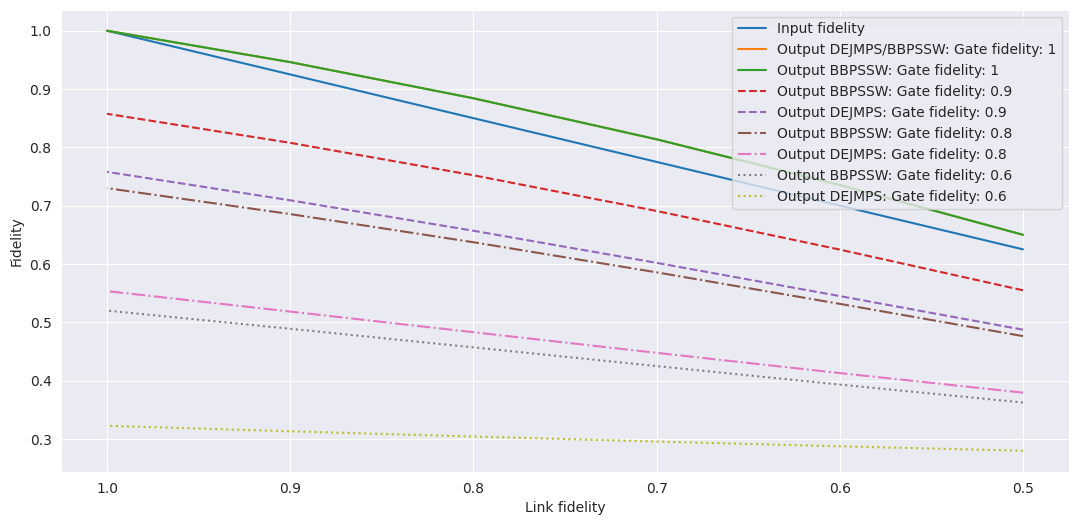

In [18]:
filtered_dataset_dejmps = extract_data(dejmps_data, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
filtered_dataset_dejmps = add_statistics(filtered_dataset_dejmps)
filtered_dataset_bbpssw = extract_data(bbpssw_data, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
filtered_dataset_bbpssw = add_statistics(filtered_dataset_bbpssw)

filtered_dataset_dejmps4 = extract_data(dejmps_data, alice_fidelity=lambda x: x==0.9, bob_fidelity=lambda x: x==0.9)
filtered_dataset_dejmps4 = add_statistics(filtered_dataset_dejmps4)
filtered_dataset_bbpssw4= extract_data(bbpssw_data, alice_fidelity=lambda x: x==0.9, bob_fidelity=lambda x: x==0.9)
filtered_dataset_bbpssw4 = add_statistics(filtered_dataset_bbpssw4)

filtered_dataset_dejmps2 = extract_data(dejmps_data, alice_fidelity=lambda x: x==0.8, bob_fidelity=lambda x: x==0.8)
filtered_dataset_dejmps2 = add_statistics(filtered_dataset_dejmps2)
filtered_dataset_bbpssw2 = extract_data(bbpssw_data, alice_fidelity=lambda x: x==0.8, bob_fidelity=lambda x: x==0.8)
filtered_dataset_bbpssw2 = add_statistics(filtered_dataset_bbpssw2)

filtered_dataset_dejmps3 = extract_data(dejmps_data, alice_fidelity=lambda x: x==0.6, bob_fidelity=lambda x: x==0.6)
filtered_dataset_dejmps3 = add_statistics(filtered_dataset_dejmps3)
filtered_dataset_bbpssw3 = extract_data(bbpssw_data, alice_fidelity=lambda x: x==0.6, bob_fidelity=lambda x: x==0.6)
filtered_dataset_bbpssw3 = add_statistics(filtered_dataset_bbpssw3)

sns.set_style("darkgrid")
plt.figure(figsize=(13,6))
plt.xlabel('Link fidelity')
plt.ylabel('Fidelity')
dejmps_link_sr = sorted(filtered_dataset_dejmps, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr2 = sorted(filtered_dataset_dejmps2, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr3 = sorted(filtered_dataset_dejmps3, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr4 = sorted(filtered_dataset_dejmps4, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr = sorted(filtered_dataset_bbpssw, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr2 = sorted(filtered_dataset_bbpssw2, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr3 = sorted(filtered_dataset_bbpssw3, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr4 = sorted(filtered_dataset_bbpssw4, key=lambda x: x['link_f'], reverse=False)
x_data_dejmps = [element['link_f'] for element in dejmps_link_sr]
y_data_dejmps = [element['avg_success_fidelity'] for element in dejmps_link_sr]
x_data_dejmps_or = [element['link_f'] for element in dejmps_link_sr]
y_data_dejmps_or = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr]

x_data_dejmps4 = [element['link_f'] for element in dejmps_link_sr4]
y_data_dejmps4 = [element['avg_success_fidelity'] for element in dejmps_link_sr4]
x_data_dejmps_or4 = [element['link_f'] for element in dejmps_link_sr4]
y_data_dejmps_or4 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr4]

x_data_dejmps2 = [element['link_f'] for element in dejmps_link_sr2]
y_data_dejmps2 = [element['avg_success_fidelity'] for element in dejmps_link_sr2]
x_data_dejmps_or2 = [element['link_f'] for element in dejmps_link_sr2]
y_data_dejmps_or2 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr2]

x_data_dejmps3 = [element['link_f'] for element in dejmps_link_sr3]
y_data_dejmps3 = [element['avg_success_fidelity'] for element in dejmps_link_sr3]
x_data_dejmps_or3 = [element['link_f'] for element in dejmps_link_sr3]
y_data_dejmps_or3 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr3]

x_data_bbpssw = [element['link_f'] for element in bbpssw_link_sr]
y_data_bbpssw = [element['avg_success_fidelity'] for element in bbpssw_link_sr]
x_data_bbpssw_or = [element['link_f'] for element in bbpssw_link_sr]
y_data_bbpssw_or = [element['avg_success_fidelity_or1'] for element in bbpssw_link_sr]

x_data_bbpssw4 = [element['link_f'] for element in bbpssw_link_sr4]
y_data_bbpssw4 = [element['avg_success_fidelity'] for element in bbpssw_link_sr4]
x_data_bbpssw_or4 = [element['link_f'] for element in bbpssw_link_sr4]
y_data_bbpssw_or4 = [element['avg_success_fidelity_or1'] for element in bbpssw_link_sr4]

x_data_bbpssw2 = [element['link_f'] for element in bbpssw_link_sr2]
y_data_bbpssw2 = [element['avg_success_fidelity'] for element in bbpssw_link_sr2]
x_data_bbpssw_or2 = [element['link_f'] for element in bbpssw_link_sr2]
y_data_bbpssw_or2 = [element['avg_success_fidelity_or1'] for element in bbpssw_link_sr2]

x_data_bbpssw3 = [element['link_f'] for element in bbpssw_link_sr3]
y_data_bbpssw3 = [element['avg_success_fidelity'] for element in bbpssw_link_sr3]
x_data_bbpssw_or3 = [element['link_f'] for element in bbpssw_link_sr3]
y_data_bbpssw_or3 = [element['avg_success_fidelity_or1'] for element in bbpssw_link_sr3]

print(y_data_dejmps)
print(y_data_bbpssw)
plt.plot(x_data_dejmps_or, y_data_dejmps_or, label='Input fidelity')

plt.plot(x_data_dejmps, y_data_dejmps, label='Output DEJMPS/BBPSSW: Gate fidelity: 1')
plt.plot(x_data_bbpssw, y_data_bbpssw, label='Output BBPSSW: Gate fidelity: 1')
plt.plot(x_data_bbpssw4, y_data_bbpssw4,label="Output BBPSSW: Gate fidelity: 0.9" , linestyle='dashed')
plt.plot(x_data_dejmps4, y_data_dejmps4, label='Output DEJMPS: Gate fidelity: 0.9', linestyle='dashed')

plt.plot(x_data_bbpssw2, y_data_bbpssw2, label='Output BBPSSW: Gate fidelity: 0.8', linestyle='-.')
plt.plot(x_data_dejmps2, y_data_dejmps2, label='Output DEJMPS: Gate fidelity: 0.8', linestyle='-.')
# plt.plot(x_data_dejmps_or2, y_data_dejmps_or2, label='Input: Gate fidelity: 0.8', linestyle='dashed')

plt.plot(x_data_bbpssw3, y_data_bbpssw3, label='Output BBPSSW: Gate fidelity: 0.6', linestyle=':')
plt.plot(x_data_dejmps3, y_data_dejmps3, label='Output DEJMPS: Gate fidelity: 0.6', linestyle=':')
# plt.plot(x_data_dejmps_or3, y_data_dejmps_or3, label='Input: Gate fidelity: 0.6', linestyle='-.')
plt.gca().invert_xaxis()
plt.legend(loc="upper right")
plt.show()

6


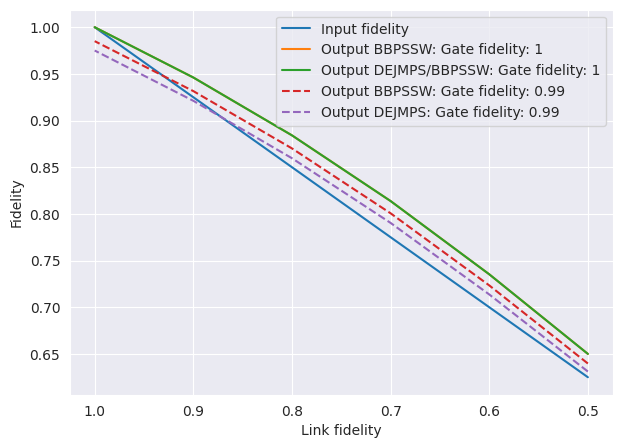

In [19]:
filtered_dataset_dejmps = extract_data(dejmps_data_focused, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
filtered_dataset_dejmps = add_statistics(filtered_dataset_dejmps)
filtered_dataset_bbpssw = extract_data(bbpssw_data_focused, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
filtered_dataset_bbpssw = add_statistics(filtered_dataset_bbpssw)

filtered_dataset_dejmps4 = extract_data(dejmps_data_focused, alice_fidelity=lambda x: x==0.99, bob_fidelity=lambda x: x==0.99)
filtered_dataset_dejmps4 = add_statistics(filtered_dataset_dejmps4)
filtered_dataset_bbpssw4= extract_data(bbpssw_data_focused, alice_fidelity=lambda x: x==0.99, bob_fidelity=lambda x: x==0.99)
filtered_dataset_bbpssw4 = add_statistics(filtered_dataset_bbpssw4)

filtered_dataset_dejmps2 = extract_data(dejmps_data_focused, alice_fidelity=lambda x: x==0.98, bob_fidelity=lambda x: x==0.98)
filtered_dataset_dejmps2 = add_statistics(filtered_dataset_dejmps2)
filtered_dataset_bbpssw2 = extract_data(bbpssw_data_focused, alice_fidelity=lambda x: x==0.98, bob_fidelity=lambda x: x==0.98)
filtered_dataset_bbpssw2 = add_statistics(filtered_dataset_bbpssw2)

filtered_dataset_dejmps3 = extract_data(dejmps_data_focused, alice_fidelity=lambda x: x==0.96, bob_fidelity=lambda x: x==0.96)
filtered_dataset_dejmps3 = add_statistics(filtered_dataset_dejmps3)
filtered_dataset_bbpssw3 = extract_data(bbpssw_data_focused, alice_fidelity=lambda x: x==0.96, bob_fidelity=lambda x: x==0.96)
filtered_dataset_bbpssw3 = add_statistics(filtered_dataset_bbpssw3)

sns.set_style("darkgrid")
plt.figure(figsize=(7,5))
plt.xlabel('Link fidelity')
plt.ylabel('Fidelity')
dejmps_link_sr = sorted(filtered_dataset_dejmps, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr2 = sorted(filtered_dataset_dejmps2, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr3 = sorted(filtered_dataset_dejmps3, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr4 = sorted(filtered_dataset_dejmps4, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr = sorted(filtered_dataset_bbpssw, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr2 = sorted(filtered_dataset_bbpssw2, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr3 = sorted(filtered_dataset_bbpssw3, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr4 = sorted(filtered_dataset_bbpssw4, key=lambda x: x['link_f'], reverse=False)
x_data_dejmps = [element['link_f'] for element in dejmps_link_sr]
y_data_dejmps = [element['avg_success_fidelity'] for element in dejmps_link_sr]
x_data_dejmps_or = [element['link_f'] for element in dejmps_link_sr]
y_data_dejmps_or = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr]

x_data_dejmps4 = [element['link_f'] for element in dejmps_link_sr4]
y_data_dejmps4 = [element['avg_success_fidelity'] for element in dejmps_link_sr4]
x_data_dejmps_or4 = [element['link_f'] for element in dejmps_link_sr4]
y_data_dejmps_or4 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr4]

x_data_dejmps2 = [element['link_f'] for element in dejmps_link_sr2]
y_data_dejmps2 = [element['avg_success_fidelity'] for element in dejmps_link_sr2]
x_data_dejmps_or2 = [element['link_f'] for element in dejmps_link_sr2]
y_data_dejmps_or2 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr2]

x_data_dejmps3 = [element['link_f'] for element in dejmps_link_sr3]
y_data_dejmps3 = [element['avg_success_fidelity'] for element in dejmps_link_sr3]
x_data_dejmps_or3 = [element['link_f'] for element in dejmps_link_sr3]
y_data_dejmps_or3 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr3]

x_data_bbpssw = [element['link_f'] for element in bbpssw_link_sr]
y_data_bbpssw = [element['avg_success_fidelity'] for element in bbpssw_link_sr]
x_data_bbpssw_or = [element['link_f'] for element in bbpssw_link_sr]
y_data_bbpssw_or = [element['avg_success_fidelity_or1'] for element in bbpssw_link_sr]

x_data_bbpssw4 = [element['link_f'] for element in bbpssw_link_sr4]
y_data_bbpssw4 = [element['avg_success_fidelity'] for element in bbpssw_link_sr4]
x_data_bbpssw_or4 = [element['link_f'] for element in bbpssw_link_sr4]
y_data_bbpssw_or4 = [element['avg_success_fidelity_or1'] for element in bbpssw_link_sr4]

x_data_bbpssw2 = [element['link_f'] for element in bbpssw_link_sr2]
y_data_bbpssw2 = [element['avg_success_fidelity'] for element in bbpssw_link_sr2]
x_data_bbpssw_or2 = [element['link_f'] for element in bbpssw_link_sr2]
y_data_bbpssw_or2 = [element['avg_success_fidelity_or1'] for element in bbpssw_link_sr2]

x_data_bbpssw3 = [element['link_f'] for element in bbpssw_link_sr3]
y_data_bbpssw3 = [element['avg_success_fidelity'] for element in bbpssw_link_sr3]
x_data_bbpssw_or3 = [element['link_f'] for element in bbpssw_link_sr3]
y_data_bbpssw_or3 = [element['avg_success_fidelity_or1'] for element in bbpssw_link_sr3]

print(len(y_data_bbpssw4))
plt.plot(x_data_dejmps_or, y_data_dejmps_or, label='Input fidelity')

plt.plot(x_data_bbpssw, y_data_bbpssw, label='Output BBPSSW: Gate fidelity: 1')
plt.plot(x_data_dejmps, y_data_dejmps, label='Output DEJMPS/BBPSSW: Gate fidelity: 1')
plt.plot(x_data_bbpssw4, y_data_bbpssw4,label="Output BBPSSW: Gate fidelity: 0.99" , linestyle='dashed')
plt.plot(x_data_dejmps4, y_data_dejmps4, label='Output DEJMPS: Gate fidelity: 0.99', linestyle='dashed')

# plt.plot(x_data_bbpssw2, y_data_bbpssw2, label='Output BBPSSW: Gate fidelity: 0.8', linestyle='-.')
# plt.plot(x_data_dejmps2, y_data_dejmps2, label='Output DEJMPS: Gate fidelity: 0.8', linestyle='-.')
# plt.plot(x_data_dejmps_or2, y_data_dejmps_or2, label='Input: Gate fidelity: 0.8', linestyle='dashed')

# plt.plot(x_data_bbpssw3, y_data_bbpssw3, label='Output BBPSSW: Gate fidelity: 0.6', linestyle=':')
# plt.plot(x_data_dejmps3, y_data_dejmps3, label='Output DEJMPS: Gate fidelity: 0.6', linestyle=':')
# plt.plot(x_data_dejmps_or3, y_data_dejmps_or3, label='Input: Gate fidelity: 0.6', linestyle='-.')
plt.gca().invert_xaxis()
plt.legend(loc="upper right")
plt.show()

6


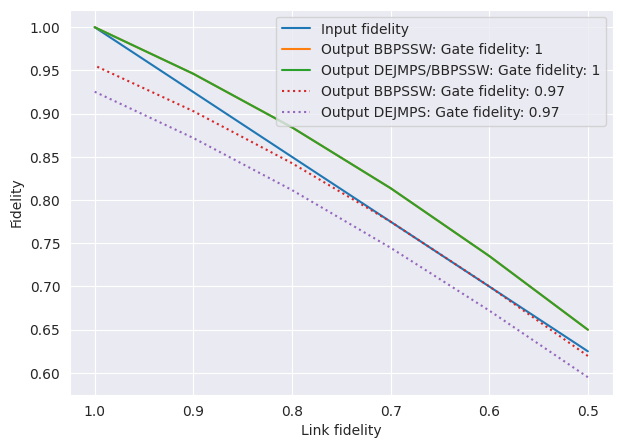

In [20]:
filtered_dataset_dejmps = extract_data(dejmps_data_focused, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
filtered_dataset_dejmps = add_statistics(filtered_dataset_dejmps)
filtered_dataset_bbpssw = extract_data(bbpssw_data_focused, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
filtered_dataset_bbpssw = add_statistics(filtered_dataset_bbpssw)

filtered_dataset_dejmps4 = extract_data(dejmps_data_focused, alice_fidelity=lambda x: x==0.99, bob_fidelity=lambda x: x==0.99)
filtered_dataset_dejmps4 = add_statistics(filtered_dataset_dejmps4)
filtered_dataset_bbpssw4= extract_data(bbpssw_data_focused, alice_fidelity=lambda x: x==0.99, bob_fidelity=lambda x: x==0.99)
filtered_dataset_bbpssw4 = add_statistics(filtered_dataset_bbpssw4)

filtered_dataset_dejmps2 = extract_data(dejmps_data_focused, alice_fidelity=lambda x: x==0.98, bob_fidelity=lambda x: x==0.98)
filtered_dataset_dejmps2 = add_statistics(filtered_dataset_dejmps2)
filtered_dataset_bbpssw2 = extract_data(bbpssw_data_focused, alice_fidelity=lambda x: x==0.98, bob_fidelity=lambda x: x==0.98)
filtered_dataset_bbpssw2 = add_statistics(filtered_dataset_bbpssw2)

filtered_dataset_dejmps3 = extract_data(dejmps_data_focused, alice_fidelity=lambda x: x==0.97, bob_fidelity=lambda x: x==0.97)
filtered_dataset_dejmps3 = add_statistics(filtered_dataset_dejmps3)
filtered_dataset_bbpssw3 = extract_data(bbpssw_data_focused, alice_fidelity=lambda x: x==0.97, bob_fidelity=lambda x: x==0.97)
filtered_dataset_bbpssw3 = add_statistics(filtered_dataset_bbpssw3)

sns.set_style("darkgrid")
plt.figure(figsize=(7,5))
plt.xlabel('Link fidelity')
plt.ylabel('Fidelity')
dejmps_link_sr = sorted(filtered_dataset_dejmps, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr2 = sorted(filtered_dataset_dejmps2, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr3 = sorted(filtered_dataset_dejmps3, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr4 = sorted(filtered_dataset_dejmps4, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr = sorted(filtered_dataset_bbpssw, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr2 = sorted(filtered_dataset_bbpssw2, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr3 = sorted(filtered_dataset_bbpssw3, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr4 = sorted(filtered_dataset_bbpssw4, key=lambda x: x['link_f'], reverse=False)
x_data_dejmps = [element['link_f'] for element in dejmps_link_sr]
y_data_dejmps = [element['avg_success_fidelity'] for element in dejmps_link_sr]
x_data_dejmps_or = [element['link_f'] for element in dejmps_link_sr]
y_data_dejmps_or = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr]

x_data_dejmps4 = [element['link_f'] for element in dejmps_link_sr4]
y_data_dejmps4 = [element['avg_success_fidelity'] for element in dejmps_link_sr4]
x_data_dejmps_or4 = [element['link_f'] for element in dejmps_link_sr4]
y_data_dejmps_or4 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr4]

x_data_dejmps2 = [element['link_f'] for element in dejmps_link_sr2]
y_data_dejmps2 = [element['avg_success_fidelity'] for element in dejmps_link_sr2]
x_data_dejmps_or2 = [element['link_f'] for element in dejmps_link_sr2]
y_data_dejmps_or2 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr2]

x_data_dejmps3 = [element['link_f'] for element in dejmps_link_sr3]
y_data_dejmps3 = [element['avg_success_fidelity'] for element in dejmps_link_sr3]
x_data_dejmps_or3 = [element['link_f'] for element in dejmps_link_sr3]
y_data_dejmps_or3 = [element['avg_success_fidelity_or1'] for element in dejmps_link_sr3]

x_data_bbpssw = [element['link_f'] for element in bbpssw_link_sr]
y_data_bbpssw = [element['avg_success_fidelity'] for element in bbpssw_link_sr]
x_data_bbpssw_or = [element['link_f'] for element in bbpssw_link_sr]
y_data_bbpssw_or = [element['avg_success_fidelity_or1'] for element in bbpssw_link_sr]

x_data_bbpssw4 = [element['link_f'] for element in bbpssw_link_sr4]
y_data_bbpssw4 = [element['avg_success_fidelity'] for element in bbpssw_link_sr4]
x_data_bbpssw_or4 = [element['link_f'] for element in bbpssw_link_sr4]
y_data_bbpssw_or4 = [element['avg_success_fidelity_or1'] for element in bbpssw_link_sr4]

x_data_bbpssw2 = [element['link_f'] for element in bbpssw_link_sr2]
y_data_bbpssw2 = [element['avg_success_fidelity'] for element in bbpssw_link_sr2]
x_data_bbpssw_or2 = [element['link_f'] for element in bbpssw_link_sr2]
y_data_bbpssw_or2 = [element['avg_success_fidelity_or1'] for element in bbpssw_link_sr2]

x_data_bbpssw3 = [element['link_f'] for element in bbpssw_link_sr3]
y_data_bbpssw3 = [element['avg_success_fidelity'] for element in bbpssw_link_sr3]
x_data_bbpssw_or3 = [element['link_f'] for element in bbpssw_link_sr3]
y_data_bbpssw_or3 = [element['avg_success_fidelity_or1'] for element in bbpssw_link_sr3]

print(len(y_data_bbpssw4))
plt.plot(x_data_dejmps_or, y_data_dejmps_or, label='Input fidelity')

plt.plot(x_data_bbpssw, y_data_bbpssw, label='Output BBPSSW: Gate fidelity: 1')
plt.plot(x_data_dejmps, y_data_dejmps, label='Output DEJMPS/BBPSSW: Gate fidelity: 1')
# plt.plot(x_data_bbpssw4, y_data_bbpssw4,label="Output BBPSSW: Gate fidelity: 0.99" , linestyle='dashed')
# plt.plot(x_data_dejmps4, y_data_dejmps4, label='Output DEJMPS: Gate fidelity: 0.99', linestyle='dashed')

# plt.plot(x_data_bbpssw2, y_data_bbpssw2, label='Output BBPSSW: Gate fidelity: 0.98', linestyle='-.')
# plt.plot(x_data_dejmps2, y_data_dejmps2, label='Output DEJMPS: Gate fidelity: 0.98', linestyle='-.')
# plt.plot(x_data_dejmps_or2, y_data_dejmps_or2, label='Input: Gate fidelity: 0.8', linestyle='dashed')

plt.plot(x_data_bbpssw3, y_data_bbpssw3, label='Output BBPSSW: Gate fidelity: 0.97', linestyle=':')
plt.plot(x_data_dejmps3, y_data_dejmps3, label='Output DEJMPS: Gate fidelity: 0.97', linestyle=':')
# plt.plot(x_data_dejmps_or3, y_data_dejmps_or3, label='Input: Gate fidelity: 0.6', linestyle='-.')
plt.gca().invert_xaxis()
plt.legend(loc="upper right")
plt.show()

[0.67, 0.67, 0.68, 0.8, 0.9, 1.0]
[0.63, 0.58, 0.73, 0.82, 0.84, 0.96]


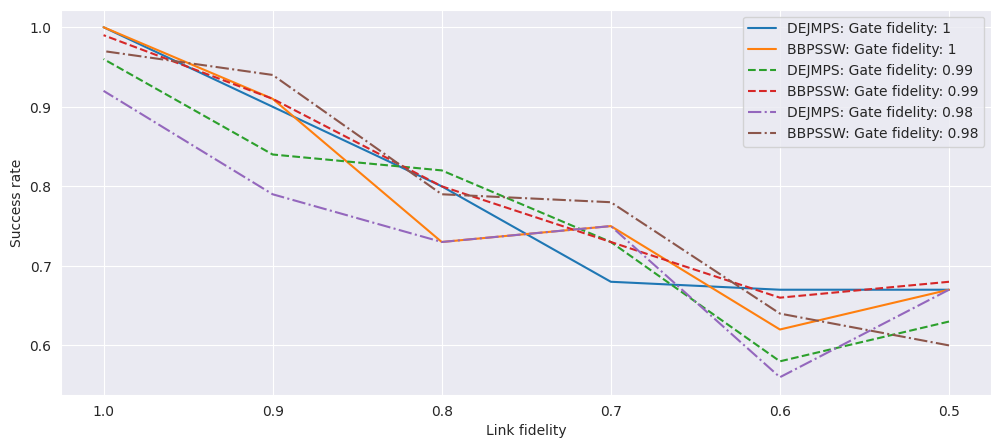

In [21]:
#DEJMPS vs BBPSSW Link fidelity - success rate

filtered_dataset_dejmps = extract_data(dejmps_data_focused, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
filtered_dataset_dejmps = add_statistics(filtered_dataset_dejmps)
filtered_dataset_bbpssw = extract_data(bbpssw_data_focused, alice_fidelity=lambda x: x==1, bob_fidelity=lambda x: x==1)
filtered_dataset_bbpssw = add_statistics(filtered_dataset_bbpssw)

filtered_dataset_dejmps2 = extract_data(dejmps_data_focused, alice_fidelity=lambda x: x==0.99, bob_fidelity=lambda x: x==0.99)
filtered_dataset_dejmps2 = add_statistics(filtered_dataset_dejmps2)
filtered_dataset_bbpssw2 = extract_data(bbpssw_data_focused, alice_fidelity=lambda x: x==0.99, bob_fidelity=lambda x: x==0.99)
filtered_dataset_bbpssw2 = add_statistics(filtered_dataset_bbpssw2)

filtered_dataset_dejmps3 = extract_data(dejmps_data_focused, alice_fidelity=lambda x: x==0.98, bob_fidelity=lambda x: x==0.98)
filtered_dataset_dejmps3 = add_statistics(filtered_dataset_dejmps3)
filtered_dataset_bbpssw3 = extract_data(bbpssw_data_focused, alice_fidelity=lambda x: x==0.98, bob_fidelity=lambda x: x==0.98)
filtered_dataset_bbpssw3 = add_statistics(filtered_dataset_bbpssw3)


sns.set_style("darkgrid")
plt.figure(figsize=(12, 5))
plt.xlabel('Link fidelity')
plt.ylabel('Success rate')
dejmps_link_sr = sorted(filtered_dataset_dejmps, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr = sorted(filtered_dataset_bbpssw, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr2 = sorted(filtered_dataset_dejmps2, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr2 = sorted(filtered_dataset_bbpssw2, key=lambda x: x['link_f'], reverse=False)
dejmps_link_sr3 = sorted(filtered_dataset_dejmps3, key=lambda x: x['link_f'], reverse=False)
bbpssw_link_sr3 = sorted(filtered_dataset_bbpssw3, key=lambda x: x['link_f'], reverse=False)
x_data_dejmps = [element['link_f'] for element in dejmps_link_sr]
y_data_dejmps = [element['success_rate'] for element in dejmps_link_sr]
x_data_bbpssw = [element['link_f'] for element in bbpssw_link_sr]
y_data_bbpssw = [element['success_rate'] for element in bbpssw_link_sr]

x_data_dejmps2 = [element['link_f'] for element in dejmps_link_sr2]
y_data_dejmps2 = [element['success_rate'] for element in dejmps_link_sr2]
x_data_bbpssw2 = [element['link_f'] for element in bbpssw_link_sr2]
y_data_bbpssw2 = [element['success_rate'] for element in bbpssw_link_sr2]

x_data_dejmps3 = [element['link_f'] for element in dejmps_link_sr3]
y_data_dejmps3 = [element['success_rate'] for element in dejmps_link_sr3]
x_data_bbpssw3 = [element['link_f'] for element in bbpssw_link_sr3]
y_data_bbpssw3 = [element['success_rate'] for element in bbpssw_link_sr3]

print(y_data_dejmps)
print(y_data_dejmps2)
plt.plot(x_data_dejmps, y_data_dejmps, label='DEJMPS: Gate fidelity: 1')
plt.plot(x_data_bbpssw, y_data_bbpssw, label='BBPSSW: Gate fidelity: 1')
plt.plot(x_data_dejmps2, y_data_dejmps2, label='DEJMPS: Gate fidelity: 0.99', linestyle='dashed')
plt.plot(x_data_bbpssw2, y_data_bbpssw2, label='BBPSSW: Gate fidelity: 0.99', linestyle='dashed')
plt.plot(x_data_dejmps3, y_data_dejmps3, label='DEJMPS: Gate fidelity: 0.98', linestyle='-.')
plt.plot(x_data_bbpssw3, y_data_bbpssw3, label='BBPSSW: Gate fidelity: 0.98', linestyle='-.')
plt.gca().invert_xaxis()
plt.legend(loc="upper right")
plt.show()